In [2]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 3 - Diffusive operator combined with a dispersive scheme

## Aim of Tutorial

The aim of this tutorial is to dive into the interest of combining a diffusive operator with a dispersive scheme. FCT and UBS methods are examples of schemes where the numerical expression of the methods contains a dispersive term and a diffusive term. Here we choose to deliberately add a diffusive operator to a solely dispersive scheme (CEN) on the saltblock experience to attest of the benefits of having both properties.

To better understand this demonstrator you should follow Demonstrator 1 beforehand.

## Running the simulations


To run the simulation we need change ```ln_traadv_cen``` from ```.false.``` to ```.true.``` and ```nn_cen_h``` and ```nn_cen_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by follwing the instructions starting 2 cells below or you can execute the cell below__

In [3]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_lap_cen2_all_grid.nc
rm CANAL_saltblock_blp_cen2_all_grid.nc
rm CANAL_saltblock_traldOFF_cen2_all_grid.nc

chmod -R a+x /"$DIR"/demo3_cfg/

sh /"$DIR"/demo3_cfg/diffusion_cfg.sh "$DIR"
sh /"$DIR"/demo3_cfg/lap_cfg.sh "$DIR"; sh /"$DIR"/demo3_cfg/blp_cfg.sh "$DIR"; sh /"$DIR"/demo3_cfg/traldfOFF_cfg.sh "$DIR"


rm: cannot remove 'CANAL_saltblock_traldOFF_cen2_all_grid.nc': No such file or directory
+ set -v
set -u #Turn on error if usinf unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ [ 1 -lt 1 ]

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ [ ! -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ]


sed -i.bak \
-e 's/rn_domszx.*=.*\!/rn_domszx      =       1000.    !/' \
-e 's/rn_domszy.*=.*\!/rn_domszy      =       1000.   !/' \
-e 's/rn_domszz.*=.*\!/rn_domszz      =       1000.  !/' \
-e 's/rn_dx.*=.*\!/rn_dx      =       20.     !/' \
-e 's/rn_dy.*=.*\!/rn_dy      =       20.  !/' \
-e 's/rn_dz.*=.*\!/rn_dz      

19c19
<    rn_domszx      =       1000.    !  x horizontal size         [km]
---
>    rn_domszx      =      	2000.    !  x horizontal size         [km]
22,23c22,23
<    rn_dx      =       20.     !  x horizontal resolution   [km]
<    rn_dy      =       20.  !  y horizontal resolution   [km]
---
>    rn_dx      =       10.     !  x horizontal resolution   [km]
>    rn_dy      =       10.  !  y horizontal resolution   [km]
35c35
<    	rn_ujetszx            =       1000.  ! width of the current [km]
---
>    	rn_ujetszx            =       2000.  ! width of the current [km]
40c40
<    nn_initcase    =     1       !  initial condition case
---
>    nn_initcase    =     2       !  initial condition case
48c48
<    ln_sshnoise  =       .false.   !  add random noise on initial ssh
---
>    ln_sshnoise  =       .true.   !  add random noise on initial ssh
57c57
<    cn_exp    =       'CANAL_diff'		!	 !  experience name
---
>    cn_exp =	'CANAL_saltblock_cen2'		!	 !  experience name



diff "$SRC" "$SRC.bak"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak

sh /"$DIR"/run_nemo.sh && echo Run CANAL_saltblock_lap_cen2_all_grid.nc completed
+ sh //net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/run_nemo.sh


57c57
<    cn_exp =  'CANAL_saltblock_lap_cen2'      		!	 !  experience name
---
>    cn_exp    =       'CANAL_diff'		!	 !  experience name
165,169c165,169
<    ln_traadv_OFF        =       .false. !  No tracer advection
<    ln_traadv_cen        =       .true.  !  2nd order centered scheme
<       nn_cen_h  =       2               !  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v  =       2               !  =2/4, vertical   2nd order CEN / 4th order COMPACT
<    ln_traadv_fct        =       .false. !  FCT scheme
---
>    ln_traadv_OFF	=	.false.	!  No tracer advection
>    ln_traadv_cen	=	.true.	!  2nd order centered scheme
>       nn_cen_h	=	2		!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v  =       2		!  =2/4, vertical   2nd order CEN / 4th order COMPACT
>    ln_traadv_fct	=	.false.	!  FCT scheme
172c172
<    ln_traadv_mus        =       .false. !  MUSCL scheme
---
>    ln_traadv_mus	=	.false.	!  MUSCL scheme
174c174
<    ln_traadv_ubs        =   

+ echo Run CANAL_saltblock_lap_cen2_all_grid.nc completed



...

Run CANAL_saltblock_blp_cen2_all_grid.nc completed


+ sed -i.bak -e s/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .true.  !/ -e s/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/ -e s/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/ -e s/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/ -e s/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/ -e s/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/ -e s/nn_cen_h.*=.*\!/nn_cen_h  =       2               !/ -e s/nn_cen_v.*=.*\!/nn_cen_v  =       2               !/ -e s/cn_exp.*=.*'.*'/cn_exp =  'CANAL_saltblock_traldfOFF_cen2'      / -e s/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .true. !/ -e s/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .false. !/ -e s/ln_traldf_blp.*=.*\!/ln_traldf_blp        =       .false. !/ namelist_cfg

diff namelist_cfg namelist_cfg.bak
+ diff namelist_cfg namelist_cfg.bak


57c57
<    cn_exp =  'CANAL_saltblock_traldfOFF_cen2'                  		!	 !  experience name
---
>    cn_exp =  'CANAL_saltblock_blp_cen2'            		!	 !  experience name
182c182
<    ln_traldf_OFF        =       .true. !  No explicit diffusion
---
>    ln_traldf_OFF        =       .false. !  No explicit diffusion
184c184
<    ln_traldf_blp        =       .false. !  bilaplacian operator
---
>    ln_traldf_blp        =       .true. !  bilaplacian operator



./run_nemo.sh
+ ./run_nemo.sh



Everything looks good



```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .true. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
```

Change the ```namusr_def``` section to the following :
  
  ```
   rn_domszx   =   1000.   !  x horizontal size         [km]
   rn_domszy   =   1000.   !  y horizontal size         [km]
   rn_domszz   =   1000.   !  z vertical size            [m]
   rn_dx       =     20.   !  x horizontal resolution   [km]
   rn_dy       =     20.  !  y horizontal resolution   [km]
   rn_dz       =   500.   !  z vertical resolution      [m]
   rn_0xratio  =      0.5  !  x-domain ratio of the 0
   rn_0yratio  =      0.5  !  y-domain ratio of the 0
   nn_fcase    =      0    !  F computation (0:f0, 1:Beta, 2:real)
   rn_ppgphi0  =      0.   !  Reference latitude      [degrees]
   rn_u10      =      0.   !  10m wind speed              [m/s]
     rn_windszx =   90.    !  longitudinal wind extension   [km]
     rn_windszy =   90.    !  latitudinal wind extension    [km]
!!clem     rn_uofac  =     0.    !  Uoce multiplicative factor (0.:absolute or 1.:relative winds)
   rn_vtxmax   =      0.5   !  initial vortex max current  [m/s]
   rn_uzonal   =     1   !  initial zonal current       [m/s]
     rn_ujetszx =   2000.  !  longitudinal jet extension   [km]
     rn_ujetszy =   2000.   !  latitudinal jet extension    [km]
   rn_salzx =	500.
   rn_salzy =	500.
   nn_botcase  =      0    !  bottom definition (0:flat, 1:bump)
   nn_initcase =      1    !  initial condition case
   !                       !          -1 : stratif at rest
   !                       !           0 : rest
   !                       !           1 : zonal current
   !                       !           2 : current shear
   !                       !           3 : gaussian zonal current
   !                       !           4 : geostrophic zonal pulse
   !                       !           5 : baroclinic vortex

   ln_sshnoise =  .false.  !  add random noise on initial ssh
   rn_lambda   =     50.   !  gaussian lambda
   ln_Iperio   =   .true.  ! i-periodicity
   ln_Jperio   =   .false.  ! j-periodicity
/
```

Set ```nn_itend``` to ```7680```

## Laplacian

To run the simulation with a laplacian operator we need change ```ln_traldf_lap``` from ```.false.``` to ```.true.```

```&namtra_ldf    !   lateral diffusion scheme for tracers                 (default: NO selection)
!-----------------------------------------------------------------------
   !                       !  Operator type:
   ln_traldf_OFF   = .false.    !  No explicit diffusion
   ln_traldf_lap   = .true.   !    laplacian operator
   ln_traldf_blp   = .false.   !  bilaplacian operator
   !
```

Change the name of the experience ```cn_exp``` to ```CANAL_saltblock_lap_cen2``` so as to not erase the data when running other simulations later on.

We can now run the simulation using the ```./run_nemo``` command

## Biaplacian

To run the simulation with a biaplacian operator we need change ```ln_traldf_blp``` from ```.false.``` to ```.true.```

```&namtra_ldf    !   lateral diffusion scheme for tracers                 (default: NO selection)
!-----------------------------------------------------------------------
   !                       !  Operator type:
   ln_traldf_OFF   = .false.    !  No explicit diffusion
   ln_traldf_lap   = .false.   !    laplacian operator
   ln_traldf_blp   = .true.   !  bilaplacian operator
   !
```

Change the name of the experience ```cn_exp``` to ```CANAL_saltblock_blp_cen2``` so as to not erase the data when running other simulations later on.

We can now run the simulation using the ```./run_nemo``` command

## Analysis of the outcome

In [12]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = 'ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/'


cen2 = xr.open_dataset(rep+'CANAL_saltblock_traldfOFF_cen2_all_grid.nc')
cen2_lap = xr.open_dataset(rep+'CANAL_saltblock_lap_cen2_all_grid.nc')
cen2_blp = xr.open_dataset(rep+'CANAL_saltblock_blp_cen2_all_grid.nc')
cen4_lap = xr.open_dataset(rep+'CANAL_saltblock_lap_cen4_all_grid.nc')
cen4_blp = xr.open_dataset(rep+'CANAL_saltblock_blp_cen4_all_grid.nc')


In [5]:
def show_t (t_list, param, title, file, rep=rep):
    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(10, 6))
    for i, t in enumerate(t_list) : 
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', cmap='coolwarm')
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])

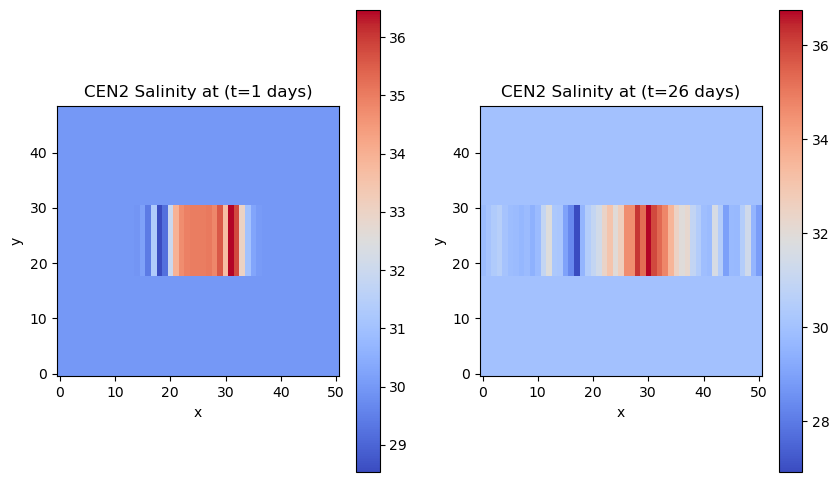

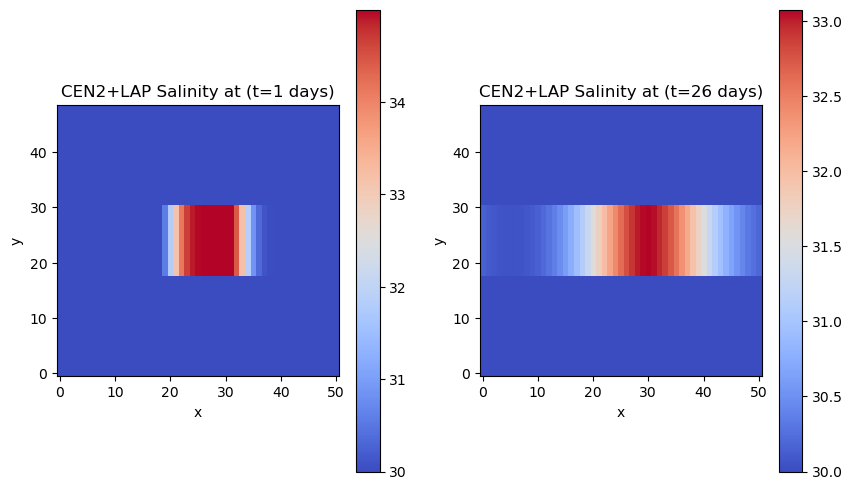

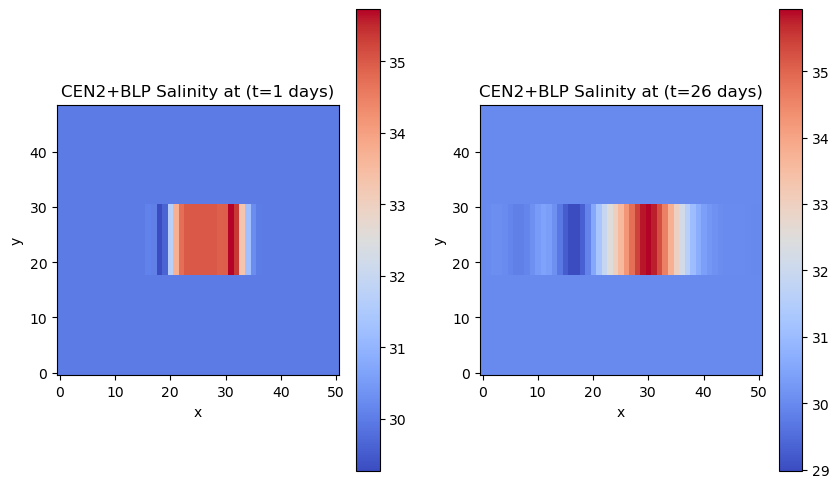

In [6]:
show_t (t_list=[0,25], param='soce', title='CEN2 Salinity', file='CANAL_saltblock_traldfOFF_cen2_all_grid.nc' , rep=rep)
show_t (t_list=[0,25], param='soce', title='CEN2+LAP Salinity', file='CANAL_saltblock_lap_cen2_all_grid.nc' , rep=rep)
show_t (t_list=[0,25], param='soce', title='CEN2+BLP Salinity', file='CANAL_saltblock_blp_cen2_all_grid.nc' , rep=rep)

        

Difficile.

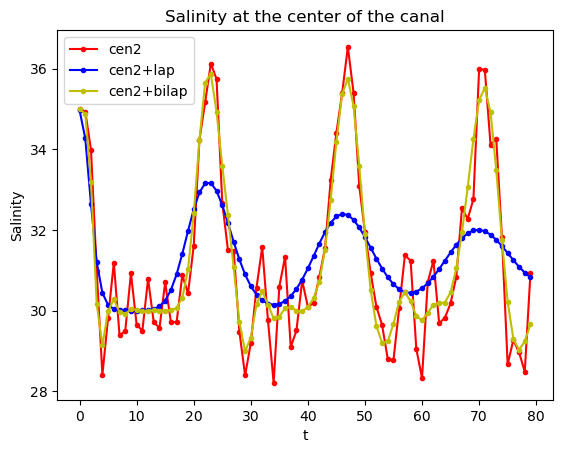

In [13]:
ymid, xmid = int(cen2['y_grid_T'].max()//2), int(cen2['x_grid_T'].max()//2)

data0 = cen2['soce'].isel(x_grid_T = xmid, y_grid_T = ymid, deptht = 0) 
dep = np.arange(data0.shape[0])
plt.plot(dep, data0, 'r.-', label = 'cen2')


ymid, xmid = int(cen2_lap['y_grid_T'].max()//2), int(cen2_lap['x_grid_T'].max()//2)

data1 = cen2_lap['soce'].isel(x_grid_T = xmid, y_grid_T = ymid, deptht = 0) 
dep = np.arange(data1.shape[0])
plt.plot(dep, data1, 'b.-', label = 'cen2+lap')


ymid, xmid = int(cen2_blp['y_grid_T'].max()//2), int(cen2_blp['x_grid_T'].max()//2)

data2 = cen2_blp['soce'].isel(x_grid_T = xmid, y_grid_T = ymid, deptht=0) 
dep = np.arange(data2.shape[0])
plt.plot(dep, data2, 'y.-', label = 'cen2+bilap')

plt.legend()
plt.title(f"Salinity at the center of the canal")
plt.xlabel('t')
plt.ylabel('Salinity')
plt.show()

We should see that the added diffusive operators should mitigate the oscillations. The laplacian should flatten the signal, the amplitude of the signal should decay and the sharp edges of the square wave should lose smooth out. The bi-laplacian should do a better job at keeping the amplitude at the same level and keeping the "sharpness" of the signal.

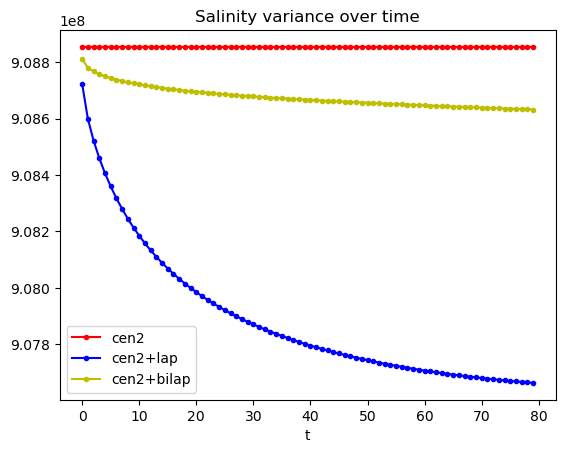

In [8]:
s2c = cen2.salt2c.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, 'r.-', label = 'cen2')


s2c = cen2_lap.salt2c.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, 'b.-', label = 'cen2+lap')


s2c = cen2_blp.salt2c.mean(dim=('x_grid_T', 'y_grid_T'))
dep = np.arange(s2c.shape[0])
plt.plot(dep,  s2c, 'y.-', label = 'cen2+bilap')

plt.title("Salinity variance over time")
plt.xlabel('t')

plt.legend()
plt.show()

The combined scheme is no longer conservative of the tracer variance. The drop for the laplacian should be deeper than the bilaplacian. This is due to the fact that the laplacian aims to dampen the signal/flatten the slopes whereas the bilaplacian aims to smooth out the curves. More "energy" is lost flattening the slopes than smoothing out the curves.

In [32]:
def side_lobes(t_list, param, title, file, mode, rep=rep):
    " show_t displays a field from an xarray at given timesteps"
    "t_list : list of the timesteps displayed"
    "param : field displayed"
    "title : title of the figure"
    "file : name of the .nc array"
    "rep : path to the file (directory mentioned above by default)"

    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(15, 6))
    for i, t in enumerate(t_list) : 
        # We select and show the side lobes of the desired field at different timesteps and at sea surface, excluding the walls
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        # Creation of a mask to highlight the side-lobes
        mask0_under = (data < 30)
        mask0_over = (data > 35)

        if mode == 'binary': 
            side_lobes = mask0_over | mask0_under
            im = axes[i].imshow(side_lobes, origin='lower', cmap= ListedColormap(['blue', 'yellow']))
            axes[i].set_title(f'Placement of the side lobes of {title} at time {t+1}')
            axes[i].set_xlabel('x')
            axes[i].set_ylabel('y')
            fig.colorbar(im, ax=axes[i])
        elif mode == 'magnitude': 
            under = data*mask0_under
            over = data*mask0_over

            under = abs(under-30)
            under = under*mask0_under

            over = abs(over-35)
            over = over*mask0_over

            side_lobes = over + under
            min_ = side_lobes.min()
            max_ = side_lobes.max()
            im = axes[i].imshow(side_lobes, origin='lower', cmap='YlOrRd', vmin = min_, vmax = max_)
            axes[i].set_title(f'Magnitude of the side lobes of {title} at time {t+1}')
            axes[i].set_xlabel('x')
            axes[i].set_ylabel('y')
            fig.colorbar(im, ax=axes[i])
        else : 
            print(f"{mode} mode does not exist")

 There were values over 35 or under 30 at timestep t = 1 : False or t = 26 : False for CEN+LAP


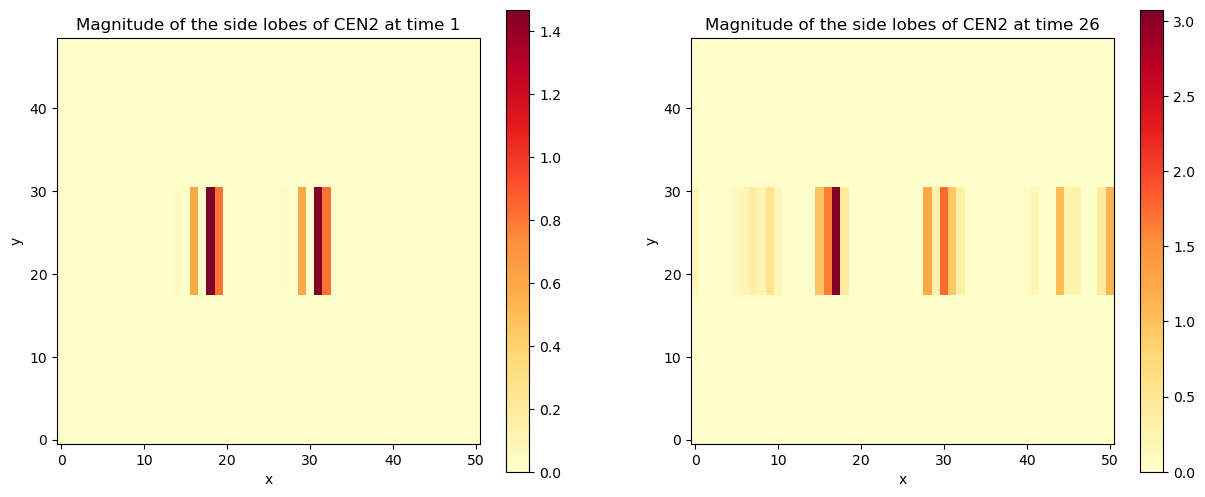

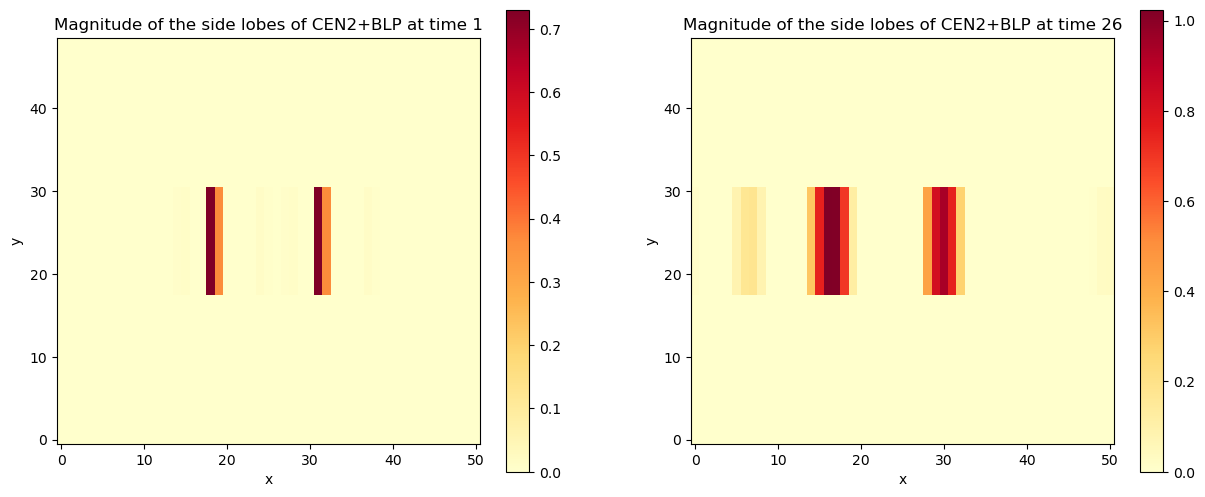

In [33]:
side_lobes([0, 25], 'soce', 'CEN2', 'CANAL_saltblock_traldfOFF_cen2_all_grid.nc', mode='magnitude', rep=rep)
side_lobes([0, 25], 'soce', 'CEN2+BLP', 'CANAL_saltblock_blp_cen2_all_grid.nc', mode='magnitude', rep=rep)

t0 = 0
t1 = 25

cen2_lap_t0 = cen2_lap.soce.isel(time_counter = t0, deptht = 0)[1:-1, :]
cen2_lap_t1 = cen2_lap.soce.isel(time_counter = t1, deptht = 0)[1:-1, :]

# Creation of a mask to highlight the side-lobes
mask0 = (cen2_lap_t0 < 30)| (cen2_lap_t0 > 35)
mask1 = (cen2_lap_t1 < 30) | (cen2_lap_t1 > 35)
# 35 was the initial value of the salt black and 30 the initial value of the background

print(f" There were values over 35 or under 30 at timestep t = {t0+1} : {bool(mask0.any())} or t = {t1+1} : {bool(mask1.any())} for CEN+LAP")


The laplacian, is positive, which means that it does not create false extrema. On the other hand, the bilaplacian allows side-lobes to be formed, though of minor importance compared to CEN2 alone.

For more explanations, see Annex 3-B.